In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
file_path = "bank-additional-full.csv"

df = pd.read_csv(file_path, sep=';')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Number of rows: 41188
Number of columns: 21

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data types:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object


In [5]:
print(df['y'].value_counts())

print("\nTarget distribution (%):")
print(df['y'].value_counts(normalize=True) * 100)

y
no     36548
yes     4640
Name: count, dtype: int64

Target distribution (%):
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nDataset information:")
df.info()

Missing values:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Duplicate records:
12

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  

In [7]:
# Display duplicate records
duplicate_rows = df[df.duplicated(keep=False)]

print("Total duplicate rows:", len(duplicate_rows))

duplicate_rows.head(10)

Total duplicate rows: 24


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


In [8]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Shape after removing duplicates: (41176, 21)
Remaining duplicates: 0


In [9]:
print("Target distribution:")
print(df['y'].value_counts())

print("\nTarget percentage:")
print(df['y'].value_counts(normalize=True) * 100)

Target distribution:
y
no     36537
yes     4639
Name: count, dtype: int64

Target percentage:
y
no     88.733728
yes    11.266272
Name: proportion, dtype: float64


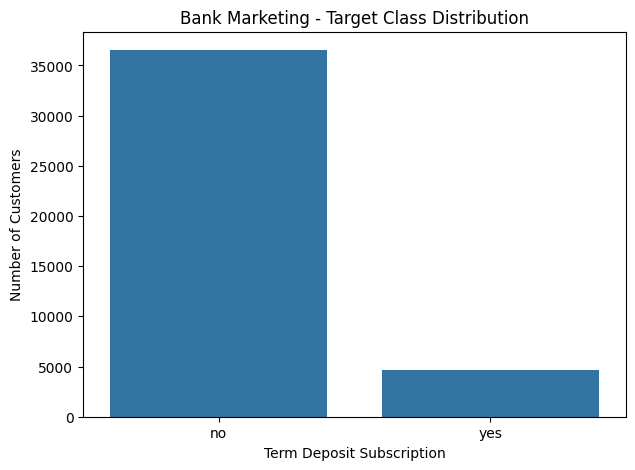

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title("Bank Marketing - Target Class Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

plt.show()

In [11]:
import os
os.makedirs("data", exist_ok=True)

df.to_csv("data/bank_marketing_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [12]:
numerical_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Numerical columns:", numerical_cols)

df[numerical_cols].describe().round(2)

Numerical columns: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41176.00,41176.00,41176.00,41176.00,41176.00,41176.00,41176.00,41176.00,41176.00,41176.00
mean,40.02,258.32,2.57,962.46,0.17,0.08,93.58,-40.50,3.62,5167.03
std,10.42,259.31,2.77,186.94,0.49,1.57,0.58,4.63,1.73,72.25
min,17.00,0.00,1.00,0.00,0.00,-3.40,92.20,-50.80,0.63,4963.60
25%,32.00,102.00,1.00,999.00,0.00,-1.80,93.08,-42.70,1.34,5099.10
50%,38.00,180.00,2.00,999.00,0.00,1.10,93.75,-41.80,4.86,5191.00
75%,47.00,319.00,3.00,999.00,0.00,1.40,93.99,-36.40,4.96,5228.10
max,98.00,4918.00,56.00,999.00,7.00,1.40,94.77,-26.90,5.04,5228.10


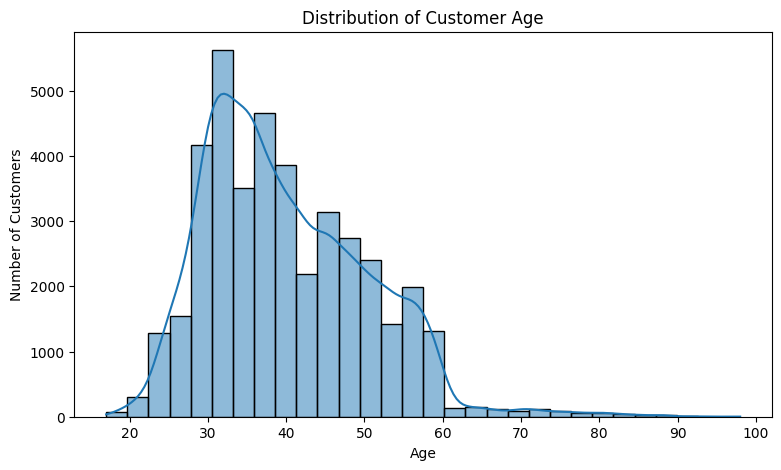

In [13]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

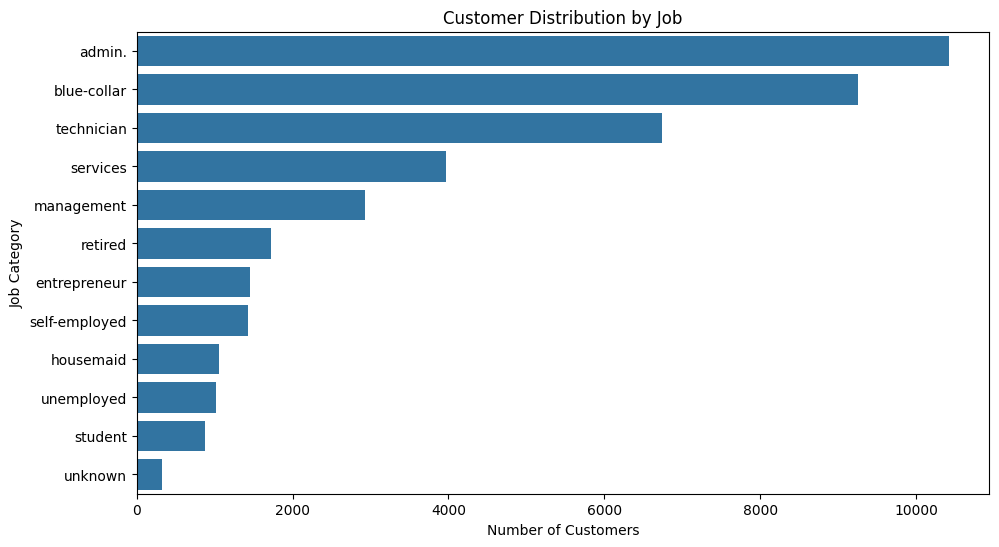

In [14]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    y='job',
    order=df['job'].value_counts().index
)

plt.title("Customer Distribution by Job")
plt.xlabel("Number of Customers")
plt.ylabel("Job Category")

plt.show()

In [15]:
job_subscription = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

job_subscription = job_subscription.sort_values(
    by='yes',
    ascending=False
)

print(job_subscription.round(2))

y                 no    yes
job                        
student        68.57  31.43
retired        74.74  25.26
unemployed     85.80  14.20
admin.         87.03  12.97
management     88.78  11.22
unknown        88.79  11.21
technician     89.17  10.83
self-employed  89.51  10.49
housemaid      90.00  10.00
entrepreneur   91.48   8.52
services       91.86   8.14
blue-collar    93.10   6.90


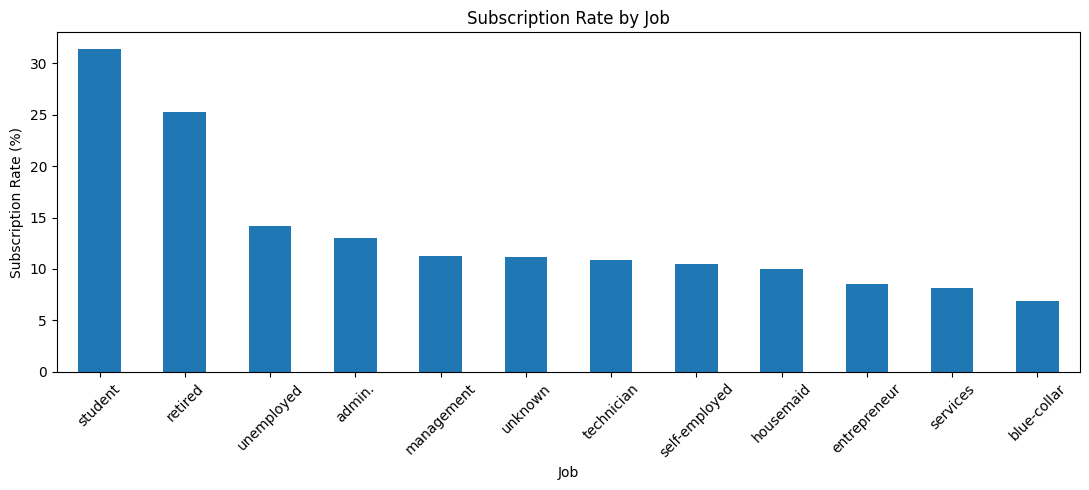

In [16]:
job_subscription['yes'].plot(
    kind='bar',
    figsize=(11, 5)
)

plt.title("Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

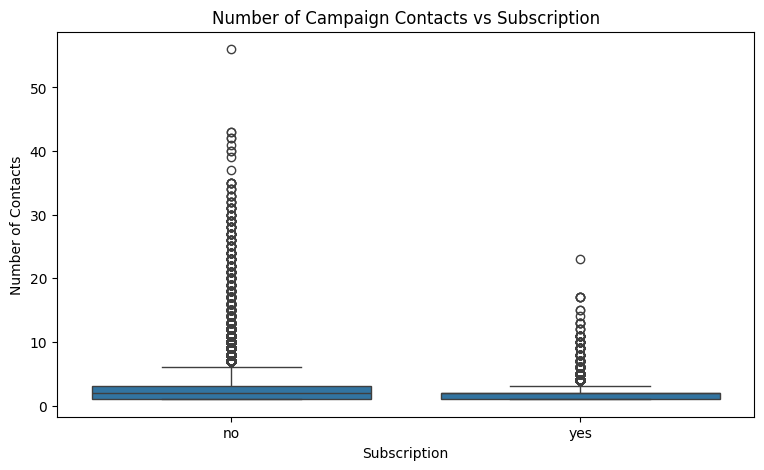

In [17]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='y', y='campaign')

plt.title("Number of Campaign Contacts vs Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Contacts")

plt.show()

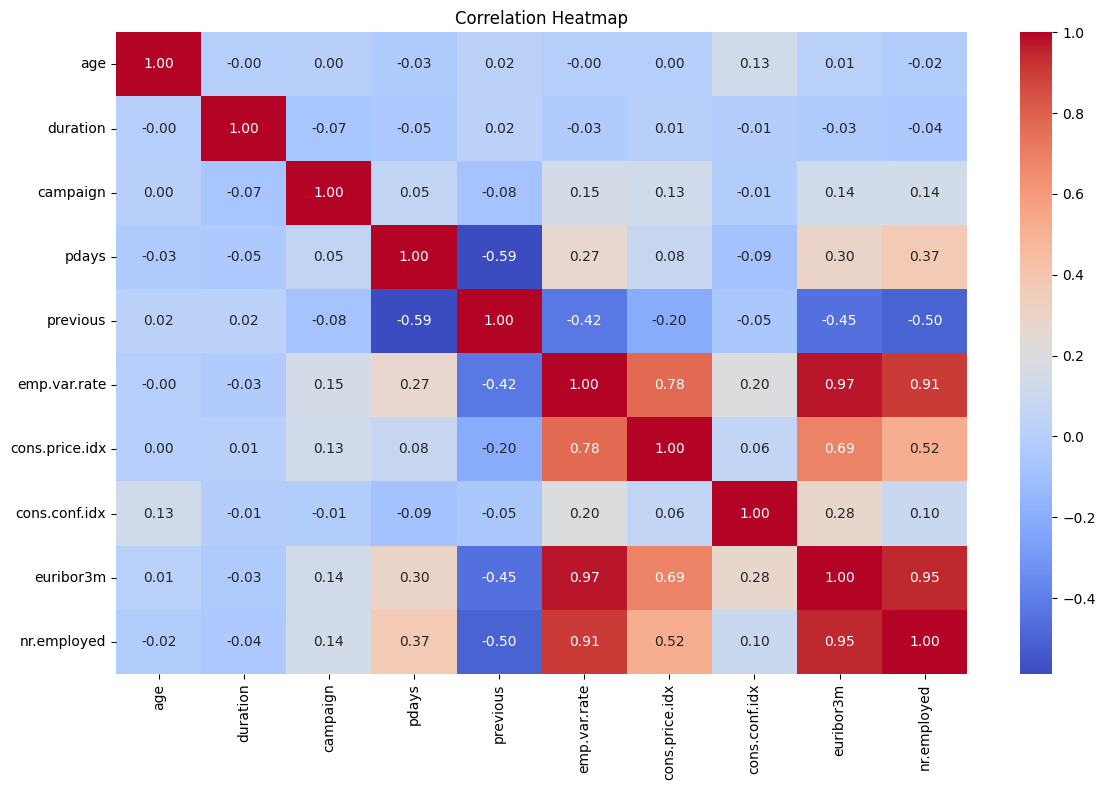

In [18]:
plt.figure(figsize=(12, 8))

correlation = df[numerical_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

In [19]:
print("pdays distribution:")

print(df['pdays'].value_counts().head(10))

print(
    "\nCustomers not previously contacted:",
    (df['pdays'] == 999).sum()
)

print(
    "\nPercentage:",
    round((df['pdays'] == 999).mean() * 100, 2),
    "%"
)

pdays distribution:
pdays
999    39661
3        439
6        412
4        118
9         64
2         61
7         60
12        58
10        52
5         46
Name: count, dtype: int64

Customers not previously contacted: 39661

Percentage: 96.32 %


In [20]:
print("pdays distribution:")
print(df['pdays'].value_counts().head(10))

print(
    "\nCustomers not previously contacted:",
    (df['pdays'] == 999).sum()
)

print(
    "\nPercentage:",
    round((df['pdays'] == 999).mean() * 100, 2),
    "%"
)

pdays distribution:
pdays
999    39661
3        439
6        412
4        118
9         64
2         61
7         60
12        58
10        52
5         46
Name: count, dtype: int64

Customers not previously contacted: 39661

Percentage: 96.32 %


In [21]:
# Create a copy of the cleaned dataset
model_df = df.copy()

# Remove duration to prevent target leakage
model_df = model_df.drop(columns=['duration'])

# Create an indicator for previous contact
model_df['previously_contacted'] = (
    model_df['pdays'] != 999
).astype(int)

# Replace special value 999 with NaN
model_df['pdays'] = model_df['pdays'].replace(999, np.nan)

# Encode target variable
model_df['y'] = model_df['y'].map({
    'no': 0,
    'yes': 1
})

print("Modelling dataset shape:", model_df.shape)

print("\nPrevious contact distribution:")
print(model_df['previously_contacted'].value_counts())

print("\nTarget distribution:")
print(model_df['y'].value_counts())

model_df.head()

Modelling dataset shape: (41176, 21)

Previous contact distribution:
previously_contacted
0    39661
1     1515
Name: count, dtype: int64

Target distribution:
y
0    36537
1     4639
Name: count, dtype: int64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0


In [22]:
X = model_df.drop(columns=['y'])
y = model_df['y']

print("Input features:", X.shape[1])
print("Target shape:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

Input features: 20
Target shape: (41176,)

Input columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training data: (32940, 20)
Testing data: (8236, 20)

Training target distribution:
y
0    88.734062
1    11.265938
Name: proportion, dtype: float64

Testing target distribution:
y
0    88.732394
1    11.267606
Name: proportion, dtype: float64


In [24]:
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 10
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']

Categorical features: 10
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [26]:
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [27]:
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ],
    remainder='drop'
)

print("Combined preprocessing pipeline created!")

Combined preprocessing pipeline created!


In [29]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (32940, 63)
Testing data after preprocessing: (8236, 63)


In [30]:
print("Training data contains NaN:",
      np.isnan(X_train_processed).any())

print("Testing data contains NaN:",
      np.isnan(X_test_processed).any())

print("Training data contains infinite values:",
      np.isinf(X_train_processed).any())

print("Testing data contains infinite values:",
      np.isinf(X_test_processed).any())

print("\nFinal number of processed features:",
      X_train_processed.shape[1])

Training data contains NaN: False
Testing data contains NaN: False
Training data contains infinite values: False
Testing data contains infinite values: False

Final number of processed features: 63


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import time

print("All model libraries imported successfully!")

All model libraries imported successfully!


In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "SVM": LinearSVC(
        max_iter=10000,
        random_state=42
    )
}

print("Five classification models created successfully!")

Five classification models created successfully!


In [33]:
trained_models = {}

training_times = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(X_train_processed, y_train)

    end_time = time.time()

    trained_models[name] = model

    training_times[name] = end_time - start_time

    print(f"{name} trained successfully!")
    print(f"Training time: {end_time - start_time:.2f} seconds")


Training Logistic Regression...
Logistic Regression trained successfully!
Training time: 3.64 seconds

Training Decision Tree...
Decision Tree trained successfully!
Training time: 0.43 seconds

Training KNN...
KNN trained successfully!
Training time: 0.01 seconds

Training Naive Bayes...
Naive Bayes trained successfully!
Training time: 0.04 seconds

Training SVM...
SVM trained successfully!
Training time: 0.65 seconds


In [36]:
results = []

for name, model in trained_models.items():

    # Predicted classes
    y_pred = model.predict(X_test_processed)

    # Get prediction scores for AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_processed)[:, 1]
    else:
        y_score = model.decision_function(X_test_processed)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(y_test, y_score)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

# Create comparison table
results_df = pd.DataFrame(results)

print("Model evaluation completed!")

results_df.round(4)

Model evaluation completed!


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8981,0.8005,0.6469,0.2112,0.3184,0.3302
1,Decision Tree,0.8418,0.6312,0.3171,0.3502,0.3328,0.2437
2,KNN,0.8951,0.7403,0.5653,0.2985,0.3907,0.3600
3,Naive Bayes,0.8230,0.7761,0.3356,0.5830,0.4260,0.3478
4,SVM,0.8993,0.7971,0.6800,0.2015,0.3109,0.3335


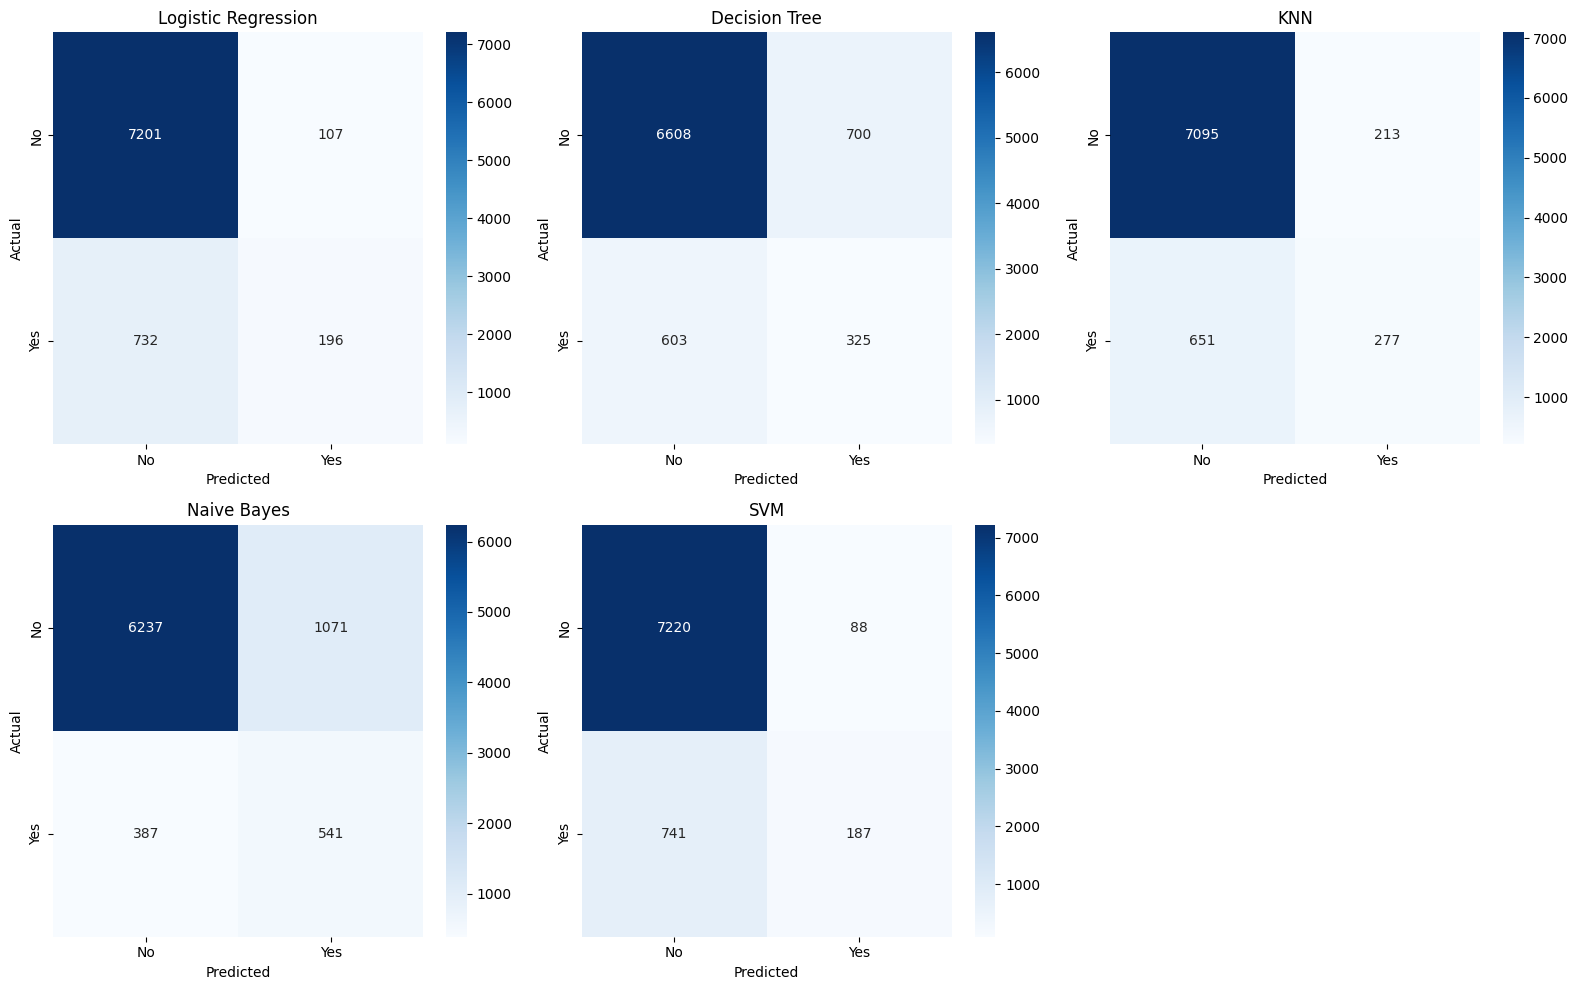

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[i],
        xticklabels=['No', 'Yes'],
        yticklabels=['No', 'Yes']
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[-1].axis('off')

plt.tight_layout()
plt.show()

In [40]:
print("Naive Bayes Classification Report:")

print(
    classification_report(
        y_test,
        trained_models["Naive Bayes"].predict(X_test_processed),
        target_names=["No", "Yes"]
    )
)

Naive Bayes Classification Report:
              precision    recall  f1-score   support

          No       0.94      0.85      0.90      7308
         Yes       0.34      0.58      0.43       928

    accuracy                           0.82      8236
   macro avg       0.64      0.72      0.66      8236
weighted avg       0.87      0.82      0.84      8236



In [42]:

import os
import joblib

os.makedirs("model", exist_ok=True)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    "model/preprocessor.joblib"
)

# Save all five trained models
for name, model in trained_models.items():

    filename = name.lower().replace(" ", "_") + ".joblib"

    joblib.dump(
        model,
        f"model/{filename}"
    )

    print(f"Saved: {filename}")

print("\nAll models and preprocessing pipeline saved!")

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: svm.joblib

All models and preprocessing pipeline saved!


In [44]:
# Combine test features and actual target
test_df = X_test.copy()

test_df['y'] = y_test

# Save test dataset
test_df.to_csv("test_data.csv", index=False)

print("Test data saved successfully!")
print("Shape:", test_df.shape)

test_df.head()

Test data saved successfully!
Shape: (8236, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,previously_contacted,y
8489,35,services,married,high.school,unknown,no,no,telephone,jun,wed,...,NaN,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,0,0
40832,30,student,single,professional.course,no,yes,no,cellular,sep,tue,...,6.0,1,success,-1.1,94.199,-37.5,0.880,4963.6,1,1
35671,37,self-employed,single,basic.4y,no,yes,no,cellular,may,mon,...,NaN,1,failure,-1.8,92.893,-46.2,1.244,5099.1,0,0
35984,31,blue-collar,single,professional.course,no,no,no,cellular,may,tue,...,NaN,0,nonexistent,-1.8,92.893,-46.2,1.266,5099.1,0,0
21954,31,technician,married,university.degree,no,unknown,unknown,cellular,aug,wed,...,NaN,0,nonexistent,1.4,93.444,-36.1,4.964,5228.1,0,0


In [46]:
results_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Comparison results saved!")

Comparison results saved!


In [48]:
print("Model files:")

for file in os.listdir("model"):
    print(file)

print("\nOther project files:")

print(os.listdir("."))

Model files:
preprocessor.joblib
logistic_regression.joblib
decision_tree.joblib
knn.joblib
naive_bayes.joblib
svm.joblib

Other project files:
['.mozilla', '.bash_logout', '.bash_profile', '.bashrc', '.config', '.cache', 'Desktop', 'Downloads', 'Templates', 'Public', 'Documents', 'Music', 'Pictures', 'Videos', '.local', '.ICEauthority', '.gnupg', '.vnc', '.Xauthority', 'thinclient_drives', '.xsession-errors.old', '.xsession-errors', '.ssh', 'anaconda3', '.conda', '.ipython', '.vscode', '.pki', '.jupyter', '.ipynb_checkpoints', '.keras', '.anaconda', '.wget-hsts', '.continuum', '.condarc', 'anaconda_projects', '.python_history', '.java', '.viminfo', '.idea', '.bash_history', '.xsession', 'workspace', 'Untitled.ipynb', 'bank-additional-full.csv', 'data', 'model', 'test_data.csv', 'model_comparison.csv']
